In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer

In [6]:
df = pd.read_csv('../data/METABRIC_RNA_Mutation.csv')



C:\Users\DANISH LAPTOP\AppData\Local\Temp\ipykernel_10248\4103849072.py:1: DtypeWarning: Columns (0: rasgef1b_mut, 1: hras_mut, 2: smarcb1_mut, 3: siah1_mut) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('../data/METABRIC_RNA_Mutation.csv')


In [7]:
df.head()

,patient_id,age_at_diagnosis,type_of_breast_surgery,cancer_type,cancer_type_detailed,cellularity,chemotherapy,pam50_+_claudin-low_subtype,cohort,er_status_measured_by_ihc,...,mtap_mut,ppp2cb_mut,smarcd1_mut,nras_mut,ndfip1_mut,hras_mut,prps2_mut,smarcb1_mut,stmn2_mut,siah1_mut
0,0,75.65,MASTECTOMY,Breast Cancer,Breast Invasive Ductal Carcinoma,NaN,0,claudin-low,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0
1,2,43.19,BREAST CONSERVING,Breast Cancer,Breast Invasive Ductal Carcinoma,High,0,LumA,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0
2,5,48.87,MASTECTOMY,Breast Cancer,Breast Invasive Ductal Carcinoma,High,1,LumB,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0
3,6,47.68,MASTECTOMY,Breast Cancer,Breast Mixed Ductal and Lobular Carcinoma,Moderate,1,LumB,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0
4,8,76.97,MASTECTOMY,Breast Cancer,Breast Mixed Ductal and Lobular Carcinoma,High,1,LumB,1.0,Positve,...,0,0,0,0,0,0,0,0,0,0


In [8]:
target = 'overall_survival'

leakage_cols = [
    'patient_id',
    'overall_survival_months',
    'death_from_cancer'
]

df = df.drop(columns=leakage_cols)

print("Dataset Shape:", df.shape)



Dataset Shape: (1904, 690)


In [9]:
X = df.drop(columns=[target])
Y = df[target]

print("X Shape:", X.shape)
print("Y Shape:", Y.shape)

X Shape: (1904, 689)
Y Shape: (1904,)


In [10]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=Y)

print("Training Data:", X_train)
print("Testing Data:", X_test)




Training Data:       age_at_diagnosis type_of_breast_surgery    cancer_type  \
1287             69.70      BREAST CONSERVING  Breast Cancer   
1602             79.20      BREAST CONSERVING  Breast Cancer   
987              72.49      BREAST CONSERVING  Breast Cancer   
1845             70.97      BREAST CONSERVING  Breast Cancer   
1833             81.14             MASTECTOMY  Breast Cancer   
...                ...                    ...            ...   
1250             72.23      BREAST CONSERVING  Breast Cancer   
600              69.48             MASTECTOMY  Breast Cancer   
923              76.06      BREAST CONSERVING  Breast Cancer   
1323             69.27      BREAST CONSERVING  Breast Cancer   
937              56.07             MASTECTOMY  Breast Cancer   

                           cancer_type_detailed cellularity  chemotherapy  \
1287  Breast Mixed Ductal and Lobular Carcinoma        High             0   
1602           Breast Invasive Ductal Carcinoma        High   

In [11]:
numerical_features = X_train.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X_train.select_dtypes(include=['object', 'string']).columns

print("Numerical Features:", len(numerical_features))
print("Categorical Features:", len(categorical_features))

Numerical Features: 500
Categorical Features: 189


In [12]:
numerical_missing = X_train[numerical_features].isnull().sum()

numerical_missing = numerical_missing[
    numerical_missing > 0
].sort_values(ascending=False)

print("Numerical columns with missing values:")
print(numerical_missing)

Numerical columns with missing values:
tumor_stage                  406
neoplasm_histologic_grade     58
mutation_count                34
tumor_size                    13
dtype: int64


In [13]:
categorical_missing = X_train[categorical_features].isnull().sum()

categorical_missing = categorical_missing[
    categorical_missing > 0
].sort_values(ascending=False)

print("Categorical columns with missing values:")
print(categorical_missing)


Categorical columns with missing values:
3-gene_classifier_subtype         166
primary_tumor_laterality           85
cellularity                        35
er_status_measured_by_ihc          18
type_of_breast_surgery             14
cancer_type_detailed               12
tumor_other_histologic_subtype     12
oncotree_code                      12
dtype: int64


In [14]:
print(X_train['tumor_stage'].value_counts(dropna=False))

tumor_stage
2.0    620
NaN    406
1.0    391
3.0     95
4.0      9
0.0      2
Name: count, dtype: int64


In [15]:
print(X_train['tumor_stage'].dtype)

float64


In [16]:
numerical_features = numerical_features.drop('tumor_stage')
categorical_features = categorical_features.append(
    pd.Index(['tumor_stage'])
)

print("Numerical Features:", len(numerical_features))
print("Categorical Features:", len(categorical_features))



Numerical Features: 499
Categorical Features: 190


In [17]:
numeric_imputer = SimpleImputer(strategy='median')

X_train_num = X_train[numerical_features].copy()
X_test_num = X_test[numerical_features].copy()

X_train_num_imputed = pd.DataFrame(
    numeric_imputer.fit_transform(X_train_num),
    columns=numerical_features,
    index=X_train.index
)

X_test_num_imputed = pd.DataFrame(
    numeric_imputer.transform(X_test_num),
    columns=numerical_features,
    index=X_test.index
)


In [18]:
categorical_imputer = SimpleImputer(strategy='most_frequent')

X_train_cat = X_train[categorical_features].copy()
X_test_cat = X_test[categorical_features].copy()

X_train_cat_imputed = pd.DataFrame(
    categorical_imputer.fit_transform(X_train_cat),
    columns=categorical_features,
    index=X_train.index
)

X_test_cat_imputed = pd.DataFrame(
    categorical_imputer.transform(X_test_cat),
    columns=categorical_features,
    index=X_test.index
)



In [19]:
print("Remaining missing values in numerical features:",
      X_train_num_imputed.isnull().sum().sum())

print("Remaining missing values in categorical features:",
      X_train_cat_imputed.isnull().sum().sum())



Remaining missing values in numerical features: 0
Remaining missing values in categorical features: 0


In [20]:
X_train_imputed = pd.concat([X_train_num_imputed, X_train_cat_imputed], axis=1)
X_test_imputed = pd.concat([X_test_num_imputed, X_test_cat_imputed], axis=1)

print("X_train:", X_train_imputed.shape)
print("X_test:", X_test_imputed.shape)



X_train: (1523, 689)
X_test: (381, 689)


In [21]:
missing_after = X_train_imputed.isnull().sum()
missing_after = missing_after[missing_after > 0]

print(missing_after)


Series([], dtype: int64)


In [22]:
mice_features = [
    'neoplasm_histologic_grade',
    'mutation_count',
    'tumor_size'
]

In [23]:
mice_imputer = IterativeImputer(
    max_iter = 10,
    random_state  = 42
)

X_train_mice = X_train[mice_features].copy()
X_test_mice = X_test[mice_features].copy()

X_train_mice_imputed = pd.DataFrame(
    mice_imputer.fit_transform(X_train_mice),
    columns=mice_features,
    index=X_train.index
)

X_test_mice_imputed = pd.DataFrame(
    mice_imputer.transform(X_test_mice),
    columns=mice_features,
    index=X_test.index
)



In [24]:
print("Remaining missing values in MICE features (train):")
print(X_train_mice_imputed.isnull().sum())


Remaining missing values in MICE features (train):
neoplasm_histologic_grade    0
mutation_count               0
tumor_size                   0
dtype: int64


In [25]:
print("Original missing values:")
print(X_train[mice_features].isnull().sum())

print("\n MICE missing values:")
print(X_train_mice_imputed.isnull().sum())

Original missing values:
neoplasm_histologic_grade    58
mutation_count               34
tumor_size                   13
dtype: int64

 MICE missing values:
neoplasm_histologic_grade    0
mutation_count               0
tumor_size                   0
dtype: int64


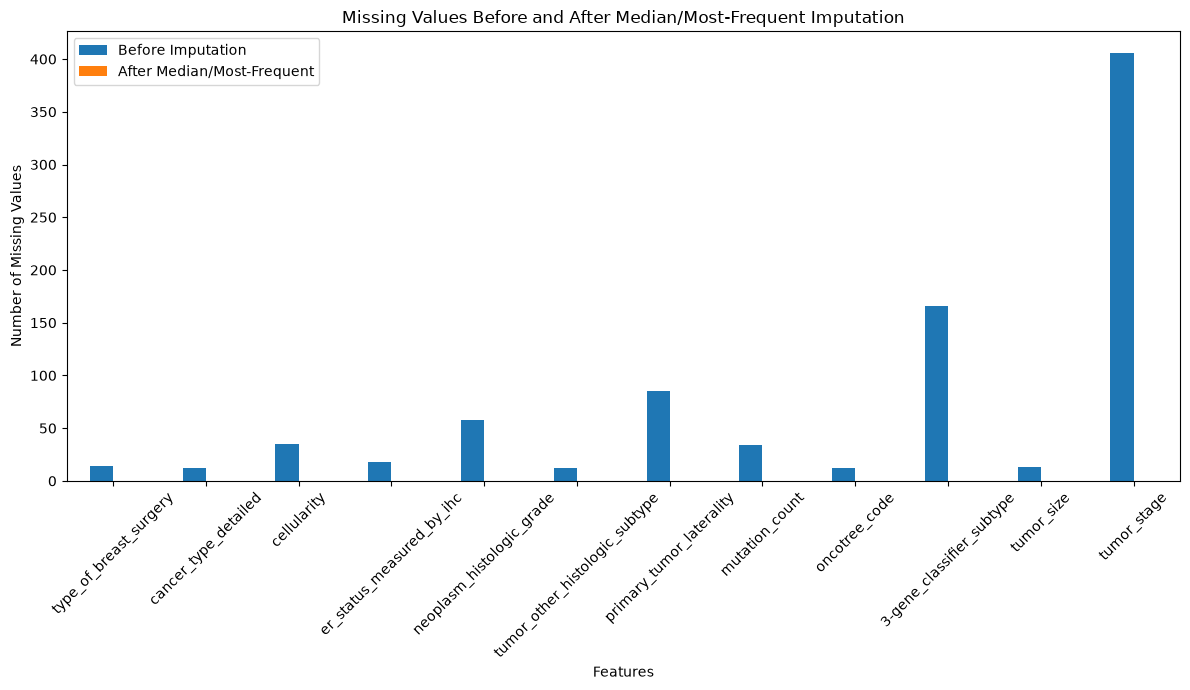

In [26]:
missing_before = X_train.isnull().sum()
missing_before = missing_before[missing_before > 0]

missing_after_median = X_train_imputed.isnull().sum()

comparison_median = pd.DataFrame({
    'Before Imputation': missing_before,
    'After Median/Most-Frequent': missing_after_median[missing_before.index]
})

comparison_median.plot(kind='bar', figsize=(12, 7))

plt.title('Missing Values Before and After Median/Most-Frequent Imputation')
plt.xlabel('Features')
plt.ylabel('Number of Missing Values')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

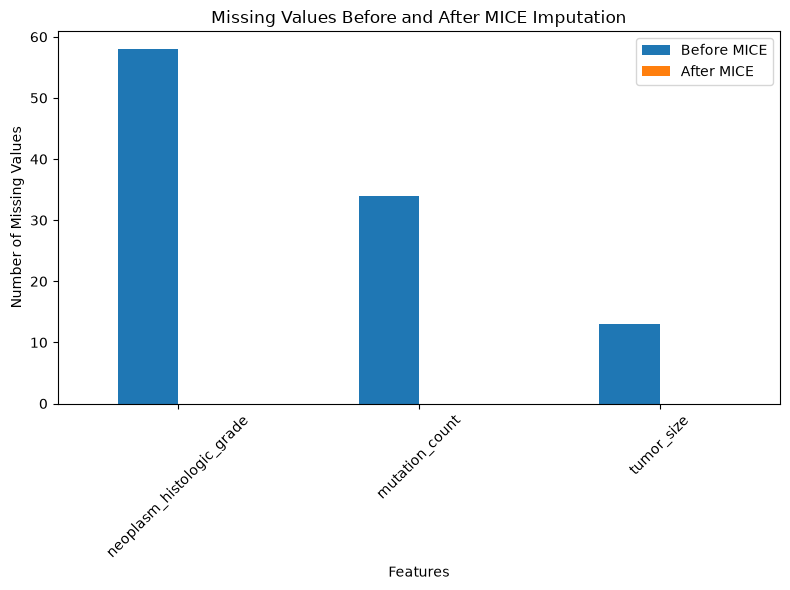

In [27]:
missing_before_mice = X_train[mice_features].isnull().sum()

missing_after_mice = X_train_mice_imputed.isnull().sum()

comparison_mice = pd.DataFrame({
    'Before MICE': missing_before_mice,
    'After MICE': missing_after_mice
})

comparison_mice.plot(kind='bar', figsize=(8, 6))

plt.title('Missing Values Before and After MICE Imputation')
plt.xlabel('Features')
plt.ylabel('Number of Missing Values')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [28]:
mice_features = [
     'neoplasm_histologic_grade',
    'mutation_count',
    'tumor_size'
]


In [29]:
comparison_values = pd.DataFrame({

    'Median Imputation': X_train_num_imputed[mice_features].loc[
        X_train[mice_features].isnull().any(axis=1)
    ].mean(),

    'MICE Imputation': X_train_mice_imputed.loc[
        X_train[mice_features].isnull().any(axis=1)
    ].mean()
})

comparison_values

,Median Imputation,MICE Imputation
neoplasm_histologic_grade,2.653846,2.330376
mutation_count,6.144231,6.379124
tumor_size,24.820192,25.177908


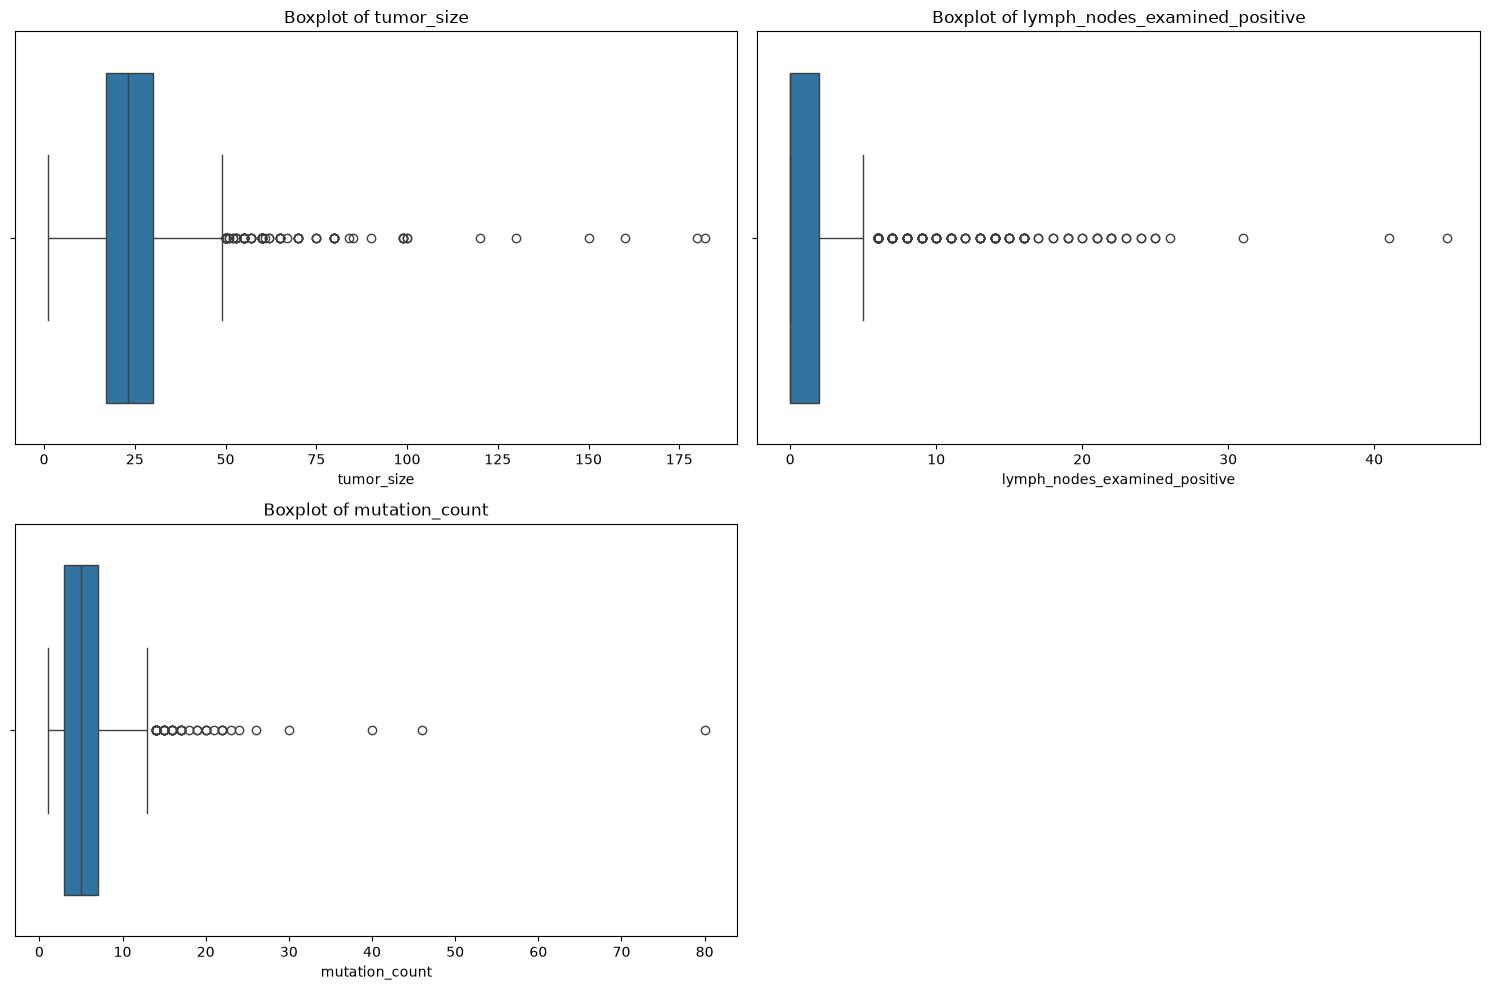

In [32]:
outlier_features = [
    'tumor_size',
    'lymph_nodes_examined_positive',
    'mutation_count'
]

plt.figure(figsize=(15,10))

for i, col in enumerate(outlier_features):

    plt.subplot(2, 2, i+1)
    sns.boxplot(x=X_train_imputed[col])
    plt.title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

In [33]:
outlier_counts = {}

for col in outlier_features:

    Q1 = X_train_imputed[col].quantile(0.25)
    Q3 = X_train_imputed[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    count = ((X_train_imputed[col] < lower) |
             (X_train_imputed[col] > upper)).sum()

    outlier_counts[col] = count

outlier_counts

{'tumor_size': np.int64(119),
 'lymph_nodes_examined_positive': np.int64(169),
 'mutation_count': np.int64(49)}

In [34]:
for col in outlier_features:

    Q1 = X_train_imputed[col].quantile(0.25)
    Q3 = X_train_imputed[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    print(f"{col}")
    print("Lower limit:", lower)
    print("Upper limit:", upper)
    print("Outliers:", ((X_train_imputed[col] < lower) |
                         (X_train_imputed[col] > upper)).sum())
    print()

tumor_size
Lower limit: -2.5
Upper limit: 49.5
Outliers: 119

lymph_nodes_examined_positive
Lower limit: -3.0
Upper limit: 5.0
Outliers: 169

mutation_count
Lower limit: -3.0
Upper limit: 13.0
Outliers: 49

